# Lesson: Pattern Supervisor — Multi-Agent con LangGraph

Partendo dalla classe `Agent` (un LLM + un tool, ciclo ReAct),
facciamo il passo successivo: **più agenti specializzati**, ognuno con i propri tool,
coordinati da un nodo Supervisor.

La struttura che costruiamo:

```
START → Supervisor → Budget → Policy → Catalogo → Aggregatore → END
            ↑ decide l'ordine      (sotto-agenti con classe Agent)
```

Ogni sotto-agente ha il **proprio grafo interno** :
```
llm ──(ha tool_calls?)──► action ──► llm ──(no tool_calls)──► END
```

## 1. Setup

In [5]:
import json
import operator
import re
from pathlib import Path
from typing import TypedDict, Annotated

from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langgraph.graph import StateGraph, START, END

llm      = ChatOllama(model="llama3.2", temperature=0)
DATA_DIR = Path("data")

with open(DATA_DIR / "employees.json") as f: EMPLOYEES_DB = json.load(f)
with open(DATA_DIR / "products.json")  as f: PRODUCTS_DB  = json.load(f)
with open(DATA_DIR / "policy_hardware.md") as f: POLICY_TEXT = f.read()

print(f"✅ Setup — dipendenti: {len(EMPLOYEES_DB)}, prodotti: {len(PRODUCTS_DB)}")


✅ Setup — dipendenti: 3, prodotti: 4


## 2. La classe `Agent`

Il grafo interno è:

```
START → llm ──(tool_calls?)──► action ──► llm ──► END
```

Ogni sotto-agente che costruiremo è un'istanza di questa classe.

In [6]:
class Agent:
    """Agente ReAct"""

    def __init__(self, model, tools, system=""):
        self.system = system

        class AgentState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        graph = StateGraph(AgentState)
        graph.add_node("llm",    self.call_llm)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()

        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state):
        """Controlla se il LLM ha richiesto almeno un tool call."""
        return len(state["messages"][-1].tool_calls) > 0

    def call_llm(self, state):
        """Nodo llm: invoca il modello con i messaggi correnti."""
        messages = state["messages"]
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {"messages": [message]}

    def take_action(self, state):
        """Nodo action: esegue i tool richiesti e raccoglie i risultati."""
        tool_calls = state["messages"][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"    🔧 {t['name']}({t['args']})")
            if t["name"] not in self.tools:
                # Hallucination del LLM — istruiamo a riprovare (come in Lesson 2)
                result = f"Tool '{t['name']}' non esiste. Disponibili: {list(self.tools.keys())}"
            else:
                result = self.tools[t["name"]].invoke(t["args"])
            results.append(ToolMessage(
                tool_call_id=t["id"], name=t["name"], content=str(result)
            ))
        return {"messages": results}

print("✅ Classe Agent definita")


✅ Classe Agent definita


## 3. Tool per ogni dominio

Ogni sotto-agente riceve solo i tool del **proprio dominio**.
In Lesson 2 c'era un unico tool di ricerca web per tutti.
Qui separiamo le responsabilità: Budget, Policy, Catalogo.

In [7]:
# ── Tool BUDGET ──────────────────────────────────────────────────────────────

@tool
def get_budget_dipendente(employee_id: str) -> str:
    """Restituisce budget residuo, ruolo e manager del dipendente.

    Args:
        employee_id: Badge ID del dipendente (es. 'E4521')
    """
    emp = EMPLOYEES_DB.get(employee_id)
    if not emp:
        return f"Dipendente '{employee_id}' non trovato nel sistema."
    return (
        f"Dipendente: {emp['name']} ({emp['role']}, {emp['department']})\n"
        f"Budget residuo: {emp['budget_residuo']} EUR\n"
        f"Progetto attivo: {emp.get('active_project', 'N/A')}\n"
        f"Manager: {emp['manager_email']}"
    )


@tool
def verifica_budget_sufficiente(employee_id: str, importo: float) -> str:
    """Verifica se il budget del dipendente copre l'importo richiesto.

    Args:
        employee_id: Badge ID del dipendente
        importo: Importo in euro da verificare
    """
    emp = EMPLOYEES_DB.get(employee_id)
    if not emp:
        return f"Dipendente '{employee_id}' non trovato."
    disponibile = emp.get("budget_residuo", 0)
    if disponibile >= importo:
        return f"✅ Budget sufficiente: {disponibile} EUR disponibili, richiesti {importo} EUR"
    return f"❌ Budget insufficiente: {disponibile} EUR disponibili, richiesti {importo} EUR"


tools_budget = [get_budget_dipendente, verifica_budget_sufficiente]
print("✅ Tools Budget:", [t.name for t in tools_budget])


✅ Tools Budget: ['get_budget_dipendente', 'verifica_budget_sufficiente']


In [8]:
# ── Tool POLICY ──────────────────────────────────────────────────────────────

@tool
def consulta_policy_hardware(categoria: str) -> str:
    """Consulta le policy aziendali per una categoria di hardware.

    Args:
        categoria: Categoria (es. 'laptop', 'monitor', 'accessory')
    """
    cat = categoria.lower()
    lines, sezione, in_sec = POLICY_TEXT.split("\n"), [], False
    for line in lines:
        if cat in line.lower() and line.startswith("##"):
            in_sec = True
        elif line.startswith("##") and in_sec:
            break
        if in_sec:
            sezione.append(line)
    return "\n".join(sezione) if sezione else POLICY_TEXT


@tool
def verifica_soglia_approvazione(ruolo: str, importo: float) -> str:
    """Verifica se l'importo supera la soglia di approvazione automatica per il ruolo.

    Args:
        ruolo: Ruolo del dipendente (es. 'Senior Developer')
        importo: Importo in euro
    """
    soglie = {
        "senior developer": 1800,
        "developer": 800,
        "manager": 2500,
        "director": 5000,
        "default": 500
    }
    soglia = soglie.get(ruolo.lower(), soglie["default"])
    if importo <= soglia:
        return f"✅ AUTO-APPROVAZIONE: {importo} EUR ≤ soglia {soglia} EUR per '{ruolo}'"
    return f"⚠️  ESCALATION: {importo} EUR > soglia {soglia} EUR per '{ruolo}'"


tools_policy = [consulta_policy_hardware, verifica_soglia_approvazione]
print("✅ Tools Policy:", [t.name for t in tools_policy])


✅ Tools Policy: ['consulta_policy_hardware', 'verifica_soglia_approvazione']


In [9]:
# ── Tool CATALOGO ─────────────────────────────────────────────────────────────

@tool
def cerca_prodotti_catalogo(query: str) -> str:
    """Cerca prodotti nel catalogo aziendale per nome o categoria.

    Args:
        query: Termine di ricerca (es. 'laptop', 'monitor', 'ThinkPad')
    """
    q = query.lower()
    risultati = {
        pid: p for pid, p in PRODUCTS_DB.items()
        if q in p.get("name", "").lower() or q in p.get("category", "").lower()
    }
    if not risultati:
        return f"Nessun prodotto trovato per '{query}'."
    righe = [f"Trovati {len(risultati)} prodotti per '{query}':"]
    for pid, p in risultati.items():
        righe.append(f"  • [{pid}] {p['name']} — {p['price_eur']} EUR ({p['category']})")
    return "\n".join(righe)


tools_catalogo = [cerca_prodotti_catalogo]
print("✅ Tools Catalogo:", [t.name for t in tools_catalogo])


✅ Tools Catalogo: ['cerca_prodotti_catalogo']


## 4. Istanziazione dei tre sotto-agenti

Ogni sotto-agente è un'istanza della classe `Agent` con i propri tool e system prompt.
L'API di utilizzo è:
```python
agente.graph.invoke({"messages": [HumanMessage(content="...")]})
```

In [10]:
agente_budget = Agent(
    model=llm,
    tools=tools_budget,
    system=(
        "Sei l'Agente Budget. Ricevi messaggi nel formato: "
        "'Verifica il budget dell\'employee <ID> per: <richiesta>'.\n"
        "Segui SEMPRE questi passi nell\'ordine:\n"
        "1. Chiama get_budget_dipendente con l\'ID del dipendente (es. 'E4521') "
        "per ottenere il budget residuo e il ruolo.\n"
        "2. Leggi il prezzo del prodotto dalla richiesta. "
        "Se il prezzo non è esplicito, stima un valore tipico per quel tipo di prodotto.\n"
        "3. Chiama verifica_budget_sufficiente con l\'ID e il prezzo stimato.\n"
        "4. Rispondi con: nome dipendente, ruolo, budget residuo, prezzo stimato, esito (sufficiente/insufficiente)."
    )
)

agente_policy = Agent(
    model=llm,
    tools=tools_policy,
    system=(
        "Sei l'Agente Policy. Ricevi messaggi nel formato: "
        "'Controlla le policy per: <richiesta>. Budget: <info_budget>'.\n"
        "Segui SEMPRE questi passi nell\'ordine:\n"
        "1. Estrai la categoria del prodotto dalla richiesta: "
        "usa UNA sola parola tra: 'laptop', 'monitor', 'accessory'. "
        "Chiama consulta_policy_hardware con quella parola.\n"
        "2. Estrai il ruolo del dipendente dalle info budget (es. 'Senior Developer'). "
        "Estrai il prezzo stimato. "
        "Chiama verifica_soglia_approvazione con ruolo e prezzo.\n"
        "3. Rispondi con: categoria, policy applicabile, soglia, esito "
        "(AUTO-APPROVAZIONE o ESCALATION)."
    )
)

agente_catalogo = Agent(
    model=llm,
    tools=tools_catalogo,
    system=(
        "Sei l'Agente Catalogo. Ricevi messaggi nel formato: "
        "'Cerca prodotti per: <richiesta>. Budget: <info_budget>'.\n"
        "Segui SEMPRE questi passi:\n"
        "1. Estrai UNA sola parola chiave dal prodotto richiesto "
        "(es. 'ThinkPad' → 'thinkpad', 'monitor 4K' → 'monitor', 'laptop' → 'laptop').\n"
        "2. Chiama cerca_prodotti_catalogo con quella singola parola chiave.\n"
        "3. Rispondi con: prodotti trovati, nome, codice, prezzo, categoria. "
        "Se non trovato, di\' esplicitamente che il prodotto non è nel catalogo."
    )
)

print('✅ Tre sotto-agenti istanziati con la classe Agent')
print('   Budget:  ', list(agente_budget.tools.keys()))
print('   Policy:  ', list(agente_policy.tools.keys()))
print('   Catalogo:', list(agente_catalogo.tools.keys()))


✅ Tre sotto-agenti istanziati con la classe Agent
   Budget:   ['get_budget_dipendente', 'verifica_budget_sufficiente']
   Policy:   ['consulta_policy_hardware', 'verifica_soglia_approvazione']
   Catalogo: ['cerca_prodotti_catalogo']


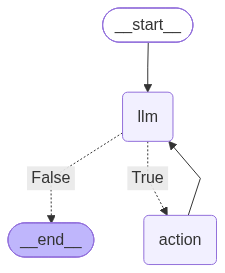

In [11]:
# Grafo interno di un sotto-agente: llm ⇄ action
try:
    from IPython.display import Image, display
    display(Image(agente_budget.graph.get_graph().draw_mermaid_png()))
except Exception:
    print(agente_budget.graph.get_graph().draw_mermaid())


### Test di un sotto-agente singolo

Invochiamo direttamente un sotto-agente con un messaggio.

In [12]:
# Test diretto dell'agente Budget
messages = [HumanMessage(content="Qual è il budget residuo del dipendente E4521?")]
result = agente_budget.graph.invoke({"messages": messages})
print(result["messages"][-1].content)


    🔧 get_budget_dipendente({'employee_id': 'E4521'})
Verifica il budget dell'employee E4521 per: acquisto di un nuovo laptop


## 5. Stato del Grafo Supervisor

Il grafo principale ha uno stato **strutturato** (diverso dal semplice `{messages:[...]}` 
dei sotto-agenti): ogni sotto-agente scrive nel **proprio campo** dedicato,
mentre `messaggi_log` si **accumula** con `operator.add`.

In [13]:
class StatoAcquisto(TypedDict):
    # Input
    richiesta_utente:   str
    employee_id:        str
    # Decisione Supervisor
    agenti_da_attivare: list[str]
    # Risultati sotto-agenti
    risultato_budget:   str
    risultato_policy:   str
    risultato_catalogo: str
    # Log accumulato (operator.add = append, non sovrascrive)
    messaggi_log:       Annotated[list[str], operator.add]
    # Output
    risposta_finale:    str
    approvato:          bool

print("✅ StatoAcquisto definito")


✅ StatoAcquisto definito


## 6. Nodi del Grafo Principale

I nodi del grafo Supervisor invocano i sotto-agenti con
`agente.graph.invoke({"messages": [...]})` — **la stessa API** del test diretto sopra.

In [14]:
def nodo_supervisor(stato: StatoAcquisto) -> dict:
    """Analizza la richiesta e decide quali agenti attivare e in quale ordine."""
    print("\n🎯 SUPERVISOR...")
    prompt = (
        f'Sei il Supervisor di un sistema multi-agente per acquisti hardware.\n'
        f'Richiesta: "{stato["richiesta_utente"]}"\n'
        f'Agenti disponibili: budget, policy, catalogo.\n'
        f'Rispondi SOLO con una lista JSON. Es: ["budget", "policy", "catalogo"]'
    )
    try:
        risposta = llm.invoke([HumanMessage(content=prompt)])
        match = re.search(r"\[.*?\]", risposta.content, re.DOTALL)
        agenti = json.loads(match.group()) if match else ["budget", "policy", "catalogo"]
    except Exception:
        agenti = ["budget", "policy", "catalogo"]
    print(f"   Agenti: {agenti}")
    return {
        "agenti_da_attivare": agenti,
        "messaggi_log": [f"[SUPERVISOR] {agenti}"]
    }


In [15]:
def nodo_agente_budget(stato: StatoAcquisto) -> dict:
    """Invoca il sotto-agente Budget e scrive il risultato nello stato."""
    print("\n💰 AGENTE BUDGET...")
    msg = (f"Verifica il budget dell'employee {stato['employee_id']} "
           f"per: {stato['richiesta_utente']}")
    result   = agente_budget.graph.invoke({"messages": [HumanMessage(content=msg)]})
    risposta = result["messages"][-1].content
    print(f"   → {risposta[:100]}...")
    return {"risultato_budget": risposta, "messaggi_log": [f"[BUDGET] {risposta[:200]}"]}


def nodo_agente_policy(stato: StatoAcquisto) -> dict:
    """Invoca il sotto-agente Policy con il contesto del budget già raccolto."""
    print("\n📋 AGENTE POLICY...")
    msg = (f"Controlla le policy per: {stato['richiesta_utente']}. "
           f"Budget: {stato.get('risultato_budget','')[:150]}")
    result   = agente_policy.graph.invoke({"messages": [HumanMessage(content=msg)]})
    risposta = result["messages"][-1].content
    print(f"   → {risposta[:100]}...")
    return {"risultato_policy": risposta, "messaggi_log": [f"[POLICY] {risposta[:200]}"]}


def nodo_agente_catalogo(stato: StatoAcquisto) -> dict:
    """Invoca il sotto-agente Catalogo con il contesto della richiesta."""
    print("\n🛍️  AGENTE CATALOGO...")
    msg = (f"Cerca prodotti per: {stato['richiesta_utente']}. "
           f"Budget: {stato.get('risultato_budget','')[:100]}")
    result   = agente_catalogo.graph.invoke({"messages": [HumanMessage(content=msg)]})
    risposta = result["messages"][-1].content
    print(f"   → {risposta[:100]}...")
    return {"risultato_catalogo": risposta, "messaggi_log": [f"[CATALOGO] {risposta[:200]}"]}


In [16]:
def nodo_aggregatore(stato: StatoAcquisto) -> dict:
    """Aggrega i risultati dei tre sotto-agenti e genera la risposta finale."""
    print("\n📊 AGGREGATORE...")
    prompt = f"""Sei il sistema di sintesi finale per acquisti hardware.
Genera una risposta strutturata basata sulle analisi.

RICHIESTA: {stato['richiesta_utente']}
BUDGET:\n{stato.get('risultato_budget', 'Non verificato')}
POLICY:\n{stato.get('risultato_policy', 'Non verificato')}
CATALOGO:\n{stato.get('risultato_catalogo', 'Non verificato')}

Indica chiaramente: APPROVATO / RIFIUTATO / APPROVAZIONE_MANUALE
Motiva la decisione e suggerisci i prodotti più adatti."""
    risposta  = llm.invoke([HumanMessage(content=prompt)])
    testo     = risposta.content.upper()
    approvato = "APPROVATO" in testo and "APPROVAZIONE_MANUALE" not in testo
    print(f"   Esito: {'✅ APPROVATO' if approvato else '⚠️  RICHIEDE ATTENZIONE'}")
    return {
        "risposta_finale": risposta.content,
        "approvato":       approvato,
        "messaggi_log":    [f"[AGGREGATORE] {'approvato' if approvato else 'non approvato'}"]
    }


## 7. Costruzione del Grafo Supervisor

Routing condizionale dopo il Supervisor: sceglie il primo agente da attivare.
Poi sequenza fissa: Budget → Policy → Catalogo → Aggregatore.

In [17]:
def routing_dopo_supervisor(stato: StatoAcquisto) -> str:
    agenti = stato.get("agenti_da_attivare", [])
    primo  = agenti[0] if agenti else "aggregatore"
    return primo if primo in ["budget", "policy", "catalogo"] else "aggregatore"


grafo = StateGraph(StatoAcquisto)

grafo.add_node("supervisor",  nodo_supervisor)
grafo.add_node("budget",      nodo_agente_budget)
grafo.add_node("policy",      nodo_agente_policy)
grafo.add_node("catalogo",    nodo_agente_catalogo)
grafo.add_node("aggregatore", nodo_aggregatore)

grafo.add_edge(START, "supervisor")
grafo.add_conditional_edges(
    "supervisor",
    routing_dopo_supervisor,
    {"budget": "budget", "policy": "policy", "catalogo": "catalogo", "aggregatore": "aggregatore"}
)
grafo.add_edge("budget",      "policy")
grafo.add_edge("policy",      "catalogo")
grafo.add_edge("catalogo",    "aggregatore")
grafo.add_edge("aggregatore", END)

app = grafo.compile()
print("✅ Grafo Supervisor compilato")


✅ Grafo Supervisor compilato


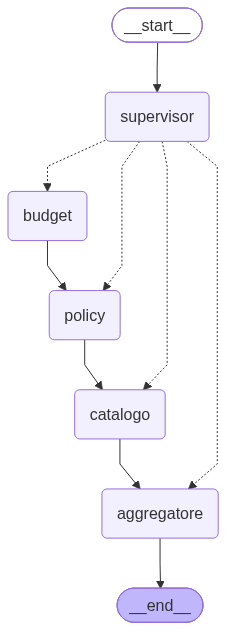

In [18]:
try:
    from IPython.display import Image, display
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    print(app.get_graph().draw_mermaid())


## 8. Esecuzione

In [19]:
def esegui(richiesta: str, employee_id: str) -> dict:
    print(f"\n{'═'*55}")
    print(f"  📥 {richiesta[:52]}")
    print(f"{'═'*55}")
    stato = {
        "richiesta_utente":   richiesta,
        "employee_id":        employee_id,
        "agenti_da_attivare": [],
        "risultato_budget":   "",
        "risultato_policy":   "",
        "risultato_catalogo": "",
        "messaggi_log":       [],
        "risposta_finale":    "",
        "approvato":          False,
    }
    risultato = app.invoke(stato)
    print(f"\n{'─'*55}")
    print("🤖 RISPOSTA FINALE:")
    print(risultato["risposta_finale"])
    return risultato


In [20]:
# Scenario 1 — Mario Rossi, ThinkPad P16s (atteso: APPROVATO)
# Budget 1800 EUR, ThinkPad 1650 EUR, Engineering ✅
r1 = esegui(
    "Ciao, sono Mario Rossi (E4521). Vorrei acquistare un ThinkPad P16s per Project Delta.",
    employee_id="E4521"
)



═══════════════════════════════════════════════════════
  📥 Ciao, sono Mario Rossi (E4521). Vorrei acquistare un
═══════════════════════════════════════════════════════

🎯 SUPERVISOR...
   Agenti: ['budget', 'catalogo', 'policy']

💰 AGENTE BUDGET...
    🔧 get_budget_dipendente({'employee_id': 'E4521'})
    🔧 verifica_budget_sufficiente({'employee_id': 'E4521', 'importo': 1500})
   → Mario Rossi (Senior Developer, Engineering)
Ruolo: Senior Developer, Engineering
Budget residuo: 180...

📋 AGENTE POLICY...
    🔧 consulta_policy_hardware({'categoria': 'ThinkPad P16s'})
    🔧 verifica_soglia_approvazione({'importo': '1500', 'ruolo': 'Senior Developer, Engineering'})
   → Ciao Mario Rossi,

La richiesta per l'acquisto del ThinkPad P16s per il progetto Project Delta è sta...

🛍️  AGENTE CATALOGO...
    🔧 cerca_prodotti_catalogo({'query': 'ThinkPad P16s'})
   → Ciao Mario Rossi (E4521), ho trovato un ThinkPad P16s che potrebbe essere adatto per i tuoi bisogni....

📊 AGGREGATORE...
   Esito: 

In [21]:
# Scenario 2 — Giulia Verdi, monitor 4K (atteso: APPROVAZIONE_MANUALE / ESCALATION)
# Budget 450 EUR, monitor 520 EUR — supera sia il budget sia la soglia 300 EUR per monitor
r2 = esegui(
    "Salve, sono Giulia Verdi (E1082). Ho bisogno del monitor 4K Dell UltraSharp per lavoro grafico.",
    employee_id="E1082"
)



═══════════════════════════════════════════════════════
  📥 Salve, sono Giulia Verdi (E1082). Ho bisogno del mon
═══════════════════════════════════════════════════════

🎯 SUPERVISOR...


   Agenti: ['budget', 'catalogo', 'policy']

💰 AGENTE BUDGET...
    🔧 get_budget_dipendente({'employee_id': 'E1082'})
    🔧 verifica_budget_sufficiente({'employee_id': 'E1082', 'importo': 999.99})
   → Salve Giulia Verdi,

Il tuo budget per il monitor 4K Dell UltraSharp per lavoro grafico è di 450 EUR...

📋 AGENTE POLICY...
    🔧 consulta_policy_hardware({'categoria': 'monitor'})
    🔧 verifica_soglia_approvazione({'ruolo': 'Senior Developer', 'importo': 450})
   → "Salve Giulia Verdi, la policy applicabile per l'acquisto del monitor 4K Dell UltraSharp è la seguen...

🛍️  AGENTE CATALOGO...
    🔧 cerca_prodotti_catalogo({'query': 'monitor 4K Dell UltraSharp'})
   → Ciao Giulia Verdi,

non abbiamo trovato il monitor 4K Dell UltraSharp nel nostro catalogo. Se deside...

📊 AGGREGATORE...
   Esito: ⚠️  RICHIEDE ATTENZIONE

───────────────────────────────────────────────────────
🤖 RISPOSTA FINALE:
**Risposta al Richiesta di Giulia Verdi**

**Informazioni sulla Richiesta**

* Nome: Giulia Ve

## 9. Riepilogo

| | Supervisor |
|---|---|
| **Agenti** | 4 (Supervisor + 3 sotto-agenti) |
| **Tool** | 5, separati per dominio |
| **Stato** | `StatoAcquisto` (TypedDict strutturato) |
| **Routing** | Esplicito (funzione Python) |
| **Ogni sotto-agente** | È un'istanza della classe `Agent` |

**Il pattern chiave**: i sotto-agenti sono grafi `llm ⇄ action`.
Il Supervisor è un grafo più grande che li orchestra come nodi.

## 10. Streaming — stato dopo ogni nodo del Supervisor

In [ ]:
print("Streaming step-by-step (nodi del grafo Supervisor):\n")
stato_test = {
    "richiesta_utente":   "Mario Rossi E4521 vuole un laptop ThinkPad",
    "employee_id":        "E4521",
    "agenti_da_attivare": [],
    "risultato_budget":   "", "risultato_policy": "", "risultato_catalogo": "",
    "messaggi_log":       [], "risposta_finale":  "", "approvato": False,
}
for step in app.stream(stato_test):
    nodo  = list(step.keys())[0]
    delta = list(step.values())[0]
    campi = [k for k in delta if k != "messaggi_log"]
    print(f"  [{nodo}] → campi aggiornati: {campi}")


Streaming step-by-step (nodi del grafo Supervisor):


🎯 SUPERVISOR...
   Agenti: ['budget', 'policy', 'catalogo']
  [supervisor] → campi aggiornati: ['agenti_da_attivare']

💰 AGENTE BUDGET...
    🔧 get_budget_dipendente({'employee_id': 'E4521'})
    🔧 verifica_budget_sufficiente({'importo': 1000, 'employee_id': 'E4521'})
   → Mario Rossi, ruolo Senior Developer, Engineering
Budget residuo: 1800 EUR
Prezzo stimato del laptop ...
  [budget] → campi aggiornati: ['risultato_budget']

📋 AGENTE POLICY...
    🔧 consulta_policy_hardware({'categoria': 'laptop'})
    🔧 verifica_soglia_approvazione({'ruolo': 'Senior Developer', 'importo': '1200'})
    🔧 verifica_soglia_approvazione({'ruolo': 'Senior Developer', 'importo': '1800'})
   → Gentile Mario Rossi,

La tua richiesta di acquisto di un laptop ThinkPad E4521 è stata approvata con...
  [policy] → campi aggiornati: ['risultato_policy']

🛍️  AGENTE CATALOGO...
    🔧 cerca_prodotti_catalogo({'query': 'ThinkPad'})
   → Ecco alcuni laptop ThinkPad

: 

## 11. Esercizi

### Esercizio A — Agente Approvazione
Aggiungi un quarto sotto-agente `agente_approvazione` con un tool che,
se `approvato=False`, stampa una notifica con l'email del manager da contattare.

### Esercizio B — Agenti in parallelo
Attualmente Budget → Policy → Catalogo sono sequenziali.
Prova a far girare Policy e Catalogo **in parallelo** dopo Budget,
poi convergere all'Aggregatore.
*(Suggerimento: due archi uscenti dallo stesso nodo creano esecuzione parallela in LangGraph.)*